## Abstract


&nbsp;&nbsp;&nbsp;&nbsp;Le but de ce projet est de développer un réseau de neurones appelé U-Net, dont la structure en forme de U lui donne son nom, et de comparer ses performances à celles de réseaux plus simples. Nous souhaitons déterminer si, dans le cadre de la segmentation d'images biomédicales, il est nécessaire de développer des architectures aussi complexes pour obtenir des performances satisfaisantes.

&nbsp;&nbsp;&nbsp;&nbsp;Dans un premier temps, nous développerons le réseau U-Net, dont nous expliquerons la structure (encodeur, goulot d'étranglement, décodeur et skip connections) avant d'analyser ses performances. Nous en proposerons également une version simplifiée, plus compacte (trois niveaux de sous-échantillonnage, jusqu'à 512 filtres) et régularisée par des couches de BatchNormalization et de Dropout. Dans un second temps, nous développerons des solutions plus traditionnelles, telles qu'un réseau convolutionnel simple, un réseau ResNet et, enfin, un réseau simplifié inspiré d'architectures plus complexes, comme Inception.

&nbsp;&nbsp;&nbsp;&nbsp;Nous analyserons ici des images de mammographie afin d'entraîner nos réseaux à segmenter les régions présentant des caractéristiques suspectes pouvant être associées à un cancer du sein. Contrairement à une simple classification, qui consiste à déterminer si une image contient ou non un cancer, la segmentation permet d'identifier et de délimiter précisément les zones suspectes au niveau des pixels, en labellisant les pixels plutôt que l'image dans son ensemble. Elle offre ainsi une information spatiale plus détaillée, permettant de localiser les anomalies au sein de l'image afin de simplifier le travail d'un spécialiste.

&nbsp;&nbsp;&nbsp;&nbsp;Nous évaluerons les performances de nos modèles à l'aide de plusieurs métriques adaptées à la segmentation : la loss, l'accuracy, la precision, le recall, le score de Dice (ou F1 au niveau des pixels), l'IoU de la classe cancéreuse, le Mean IoU, ainsi que l'AUC ROC et l'AUC PR. L'accuracy seule étant trompeuse lorsque les pixels de fond sont très largement majoritaires, nous accorderons plus d'importance au Dice et à l'IoU, qui mesurent la qualité du recouvrement entre la zone prédite et la zone réelle, et à l'AUC PR, plus informative que l'AUC ROC lorsque la classe d'intérêt est minoritaire. Une attention particulière sera portée à la maximisation du recall, afin de limiter les faux négatifs, c'est-à-dire les régions cancéreuses qui ne seraient pas détectées par le modèle. Cet enjeu est particulièrement important dans le domaine médical, où l'absence de détection d'une anomalie peut avoir des conséquences significatives sur le diagnostic et la prise en charge des patientes. Ce recall devra néanmoins être mis en regard de la precision, afin de ne pas multiplier les fausses alertes qui alourdiraient le travail du spécialiste.

&nbsp;&nbsp;&nbsp;&nbsp;Afin de garantir la reproductibilité des résultats et la comparabilité des modèles, une seed globale est fixée pour l'ensemble du notebook.

# Partie 1 : Developpement du UNet 

## Description du réseau 

&nbsp;&nbsp;&nbsp;&nbsp; Le réseau U-Net est un réseau de neurones convolutif dont l'architecture repose sur deux parties complémentaires : un encodeur, qui réduit progressivement la résolution spatiale de l'image, et un décodeur, qui permet de reconstruire progressivement sa résolution initiale grâce à des convolutions transposées (up-convolutions).

&nbsp;&nbsp;&nbsp;&nbsp; L'encodeur est composé de quatre blocs successifs. Chacun de ces blocs contient deux couches de convolution de taille 3 × 3, suivies d'une fonction d'activation ReLU. À la fin de chaque bloc, une opération de max pooling de taille 2 × 2 est appliquée afin de réduire de moitié la résolution spatiale de l'image et d'extraire des caractéristiques de plus en plus abstraites.

&nbsp;&nbsp;&nbsp;&nbsp; Une particularité essentielle de l'architecture U-Net réside dans ses connexions de saut (skip connections). À la sortie de chaque bloc de l'encodeur, les caractéristiques extraites sont copiées puis recadrées (cropped) afin d'être transmises au bloc correspondant du décodeur. Ces connexions permettent de conserver les informations spatiales détaillées perdues lors de la réduction de résolution et de les réutiliser pendant la reconstruction.

&nbsp;&nbsp;&nbsp;&nbsp; Le bloc le plus profond du réseau, situé entre l'encodeur et le décodeur, constitue le point de transition de l'architecture. Il est composé de deux couches de convolution de taille 3 × 3, chacune suivie d'une fonction d'activation ReLU. Il permet d'extraire les caractéristiques les plus abstraites de l'image avant d'entamer la phase de reconstruction.

&nbsp;&nbsp;&nbsp;&nbsp; Le décodeur constitue la seconde partie du réseau. À chaque étage, la résolution spatiale est augmentée grâce à une convolution transposée (up-convolution) de taille 2 × 2. Les caractéristiques obtenues sont ensuite concaténées avec celles provenant de la connexion de saut correspondante de l'encodeur. Chaque bloc du décodeur est alors composé de deux couches de convolution de taille 3 × 3, suivies chacune d'une fonction d'activation ReLU.

&nbsp;&nbsp;&nbsp;&nbsp; Enfin, une dernière convolution 1 x 1 permet de projeter les caractéristiques obtenues sur le nombre de classes souhaité, afin d'attribuer à chaque pixel de l'image une classe et de produire ainsi la segmentation finale.

<p align="center">
    <img src="Unet.png"  width="800">
</p>

In [3]:
import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns; sns.set(style="whitegrid")
from pathlib import Path

SEED = 2026

os.environ["PYTHONHASHSEED"] = str(SEED)
keras.utils.set_random_seed(SEED)           # fixe random, numpy et tensorflow d'un coup
tf.config.experimental.enable_op_determinism()  # force des opérations GPU déterministes

In [4]:
# --- Configuration ---------------------------------------------------------
DATA_DIR = Path("data/raw/membrane")
TRAIN_DIR = DATA_DIR / "train"
IMAGE_DIR = TRAIN_DIR / "image"
LABEL_DIR = TRAIN_DIR / "label"
TEST_DIR = DATA_DIR / "test"

INPUT_SIZE = 572
OUTPUT_SIZE = 388
VALIDATION_SIZE = 0.2
RANDOM_STATE = 42

CROP_START = (INPUT_SIZE - OUTPUT_SIZE) // 2
CROP_END = CROP_START + OUTPUT_SIZE


# --- Fonctions utilitaires -------------------------------------------------
def numeric_sort_key(path: Path) -> int:
    return int(path.stem)


def load_image(path: Path) -> np.ndarray:
    """Charge une image PNG en niveaux de gris, redimensionnée et normalisée dans [0, 1]."""
    image = tf.io.decode_png(tf.io.read_file(str(path)), channels=1)
    image = tf.image.resize(image, [INPUT_SIZE, INPUT_SIZE], method="bilinear")
    return (image / 255.0).numpy().astype(np.float32)


def load_mask(path: Path) -> np.ndarray:
    """Charge un masque binaire, redimensionné puis recadré au centre (taille de sortie de l'U-Net)."""
    mask = tf.io.decode_png(tf.io.read_file(str(path)), channels=1)
    mask = tf.cast(mask > 0, tf.float32)
    mask = tf.image.resize(mask, [INPUT_SIZE, INPUT_SIZE], method="nearest")
    return mask.numpy()[CROP_START:CROP_END, CROP_START:CROP_END, 0].astype(np.uint8)


# --- Vérification des dossiers ---------------------------------------------
for directory in (IMAGE_DIR, LABEL_DIR, TEST_DIR):
    if not directory.is_dir():
        raise FileNotFoundError(f"Dossier introuvable : {directory.resolve()}")

# --- Listage des fichiers --------------------------------------------------
image_paths = sorted(IMAGE_DIR.glob("*.png"), key=numeric_sort_key)
label_paths = {path.stem: path for path in LABEL_DIR.glob("*.png")}
# Les fichiers *_predict.png contiennent les masques de test.
test_image_paths = sorted(
    (p for p in TEST_DIR.glob("*.png") if not p.stem.endswith("_predict")),
    key=numeric_sort_key,
)
test_mask_paths = {
    p.stem.removesuffix("_predict"): p
    for p in TEST_DIR.glob("*_predict.png")
}

if len(image_paths) < 2:
    raise ValueError("Il faut au moins deux images pour créer train et validation.")
if not test_image_paths:
    raise ValueError(f"Aucune image de test trouvée dans {TEST_DIR.resolve()}.")
if {p.stem for p in test_image_paths} != test_mask_paths.keys():
    raise ValueError("Les noms des images et des masques de test ne correspondent pas.")
if {p.stem for p in image_paths} != label_paths.keys():
    raise ValueError("Les noms des images et des masques ne correspondent pas.")

# --- Chargement Train ------------------------------------------------------------
X = np.stack([load_image(p) for p in image_paths])
y = np.stack([load_mask(label_paths[p.stem]) for p in image_paths])

# --- Split train / validation ----------------------------------------------
indices = np.random.default_rng(RANDOM_STATE).permutation(len(X))
n_val = max(1, int(np.ceil(len(X) * VALIDATION_SIZE)))
val_idx, train_idx = indices[:n_val], indices[n_val:]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]

# --- Chargement Test -------------------------------------------------------------
X_test = np.stack([load_image(p) for p in test_image_paths])
y_test = np.stack([load_mask(test_mask_paths[p.stem]) for p in test_image_paths])


print(f"X_train : {X_train.shape} | y_train : {y_train.shape}")
print(f"X_val   : {X_val.shape} | y_val   : {y_val.shape}")
print(f"X_test  : {X_test.shape} | y_test  : {y_test.shape}")

X_train : (24, 572, 572, 1) | y_train : (24, 388, 388)
X_val   : (6, 572, 572, 1) | y_val   : (6, 388, 388)
X_test  : (30, 572, 572, 1) | y_test  : (30, 388, 388)


In [5]:
def conv_block(x, filters):
    """2 convolutions 3x3 + ReLU (valid) : enlève 4 pixels."""
    x = keras.layers.Conv2D(filters, 3, activation="relu", padding="valid")(x)
    x = keras.layers.Conv2D(filters, 3, activation="relu", padding="valid")(x)
    return x


def up_block(x, skip, filters, crop):
    """up-conv 2x2 -> crop du skip -> concat -> 2 convs 3x3."""
    x = keras.layers.Conv2DTranspose(filters, 2, strides=2)(x)
    skip = keras.layers.Cropping2D(crop)(skip)   # recadre le skip au centre
    x = keras.layers.Concatenate()([skip, x])
    return conv_block(x, filters)


def get_model(input_shape=(572, 572, 1), num_classes=2):
    inputs = keras.Input(input_shape)                           # 572

    # Encodeur (x1..x4 gardés pour les skip connections)
    x1 = conv_block(inputs, 64)                                 # 568
    x2 = conv_block(keras.layers.MaxPooling2D(2)(x1), 128)      # 280
    x3 = conv_block(keras.layers.MaxPooling2D(2)(x2), 256)      # 136
    x4 = conv_block(keras.layers.MaxPooling2D(2)(x3), 512)      # 64

    # Bottleneck
    b = conv_block(keras.layers.MaxPooling2D(2)(x4), 1024)      # 28

    # Décodeur : crop = (taille du skip - taille après up-conv) / 2
    d4 = up_block(b,  x4, 512, crop=4)                          # 52
    d3 = up_block(d4, x3, 256, crop=16)                         # 100
    d2 = up_block(d3, x2, 128, crop=40)                         # 196
    d1 = up_block(d2, x1, 64,  crop=88)                         # 388

    outputs = keras.layers.Conv2D(num_classes, 1, activation="softmax")(d1)   # 388x388x2
    
    model =keras.Model(inputs, outputs, name="unet")
    return model


model = get_model()
model.summary()

Model: "unet"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 572, 572, 1  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 570, 570, 64  640         ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 conv2d_1 (Conv2D)              (None, 568, 568, 64  36928       ['conv2d[0][0]']                 
                                )                                                              

In [6]:
callback = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5)

n_epochs = 5
baches_size = 5

y_train_one_hot = tf.one_hot(y_train, depth=2)
y_val_one_hot = tf.one_hot(y_val, depth=2)

model.compile(
    optimizer="adam",              # garde les tiens
    loss="categorical_crossentropy",  # garde le tien
    metrics=[
        keras.metrics.CategoricalAccuracy(name="accuracy"),
        keras.metrics.Precision(class_id=1, name="precision"),
        keras.metrics.Recall(class_id=1, name="recall"),
        keras.metrics.AUC(name="auc"),
        keras.metrics.AUC(curve="PR", name="auc_pr"),
        keras.metrics.OneHotIoU(num_classes=2, target_class_ids=[1], name="iou_fg"),
        keras.metrics.OneHotMeanIoU(num_classes=2, name="mean_iou"),
    ],
)

history = model.fit(
    X_train,
    y_train_one_hot,
    epochs=n_epochs,
    batch_size=baches_size,
    validation_data=(X_val, y_val_one_hot),
    callbacks=[callback],
)

Epoch 1/5
24/24 [==============================] - 6s 147ms/step - loss: 0.6685 - accuracy: 0.7408 - precision: 0.7617 - recall: 0.9602 - auc: 0.8097 - auc_pr: 0.7849 - iou_fg: 0.4706 - mean_iou: 0.2998 - val_loss: 0.4363 - val_accuracy: 0.7901 - val_precision: 0.7901 - val_recall: 1.0000 - val_auc: 0.9128 - val_auc_pr: 0.9180 - val_iou_fg: 0.4000 - val_mean_iou: 0.3538
Epoch 2/5
24/24 [==============================] - 3s 110ms/step - loss: 0.4651 - accuracy: 0.7688 - precision: 0.7723 - recall: 0.9877 - auc: 0.8661 - auc_pr: 0.8678 - iou_fg: 0.3871 - mean_iou: 0.3481 - val_loss: 0.4006 - val_accuracy: 0.7896 - val_precision: 0.7933 - val_recall: 0.9921 - val_auc: 0.9139 - val_auc_pr: 0.9191 - val_iou_fg: 0.3333 - val_mean_iou: 0.3333
Epoch 3/5
24/24 [==============================] - 3s 110ms/step - loss: 0.3953 - accuracy: 0.7986 - precision: 0.8288 - recall: 0.9272 - auc: 0.9000 - auc_pr: 0.9051 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 0.4086 - val_accuracy: 0.7924 - val_pre

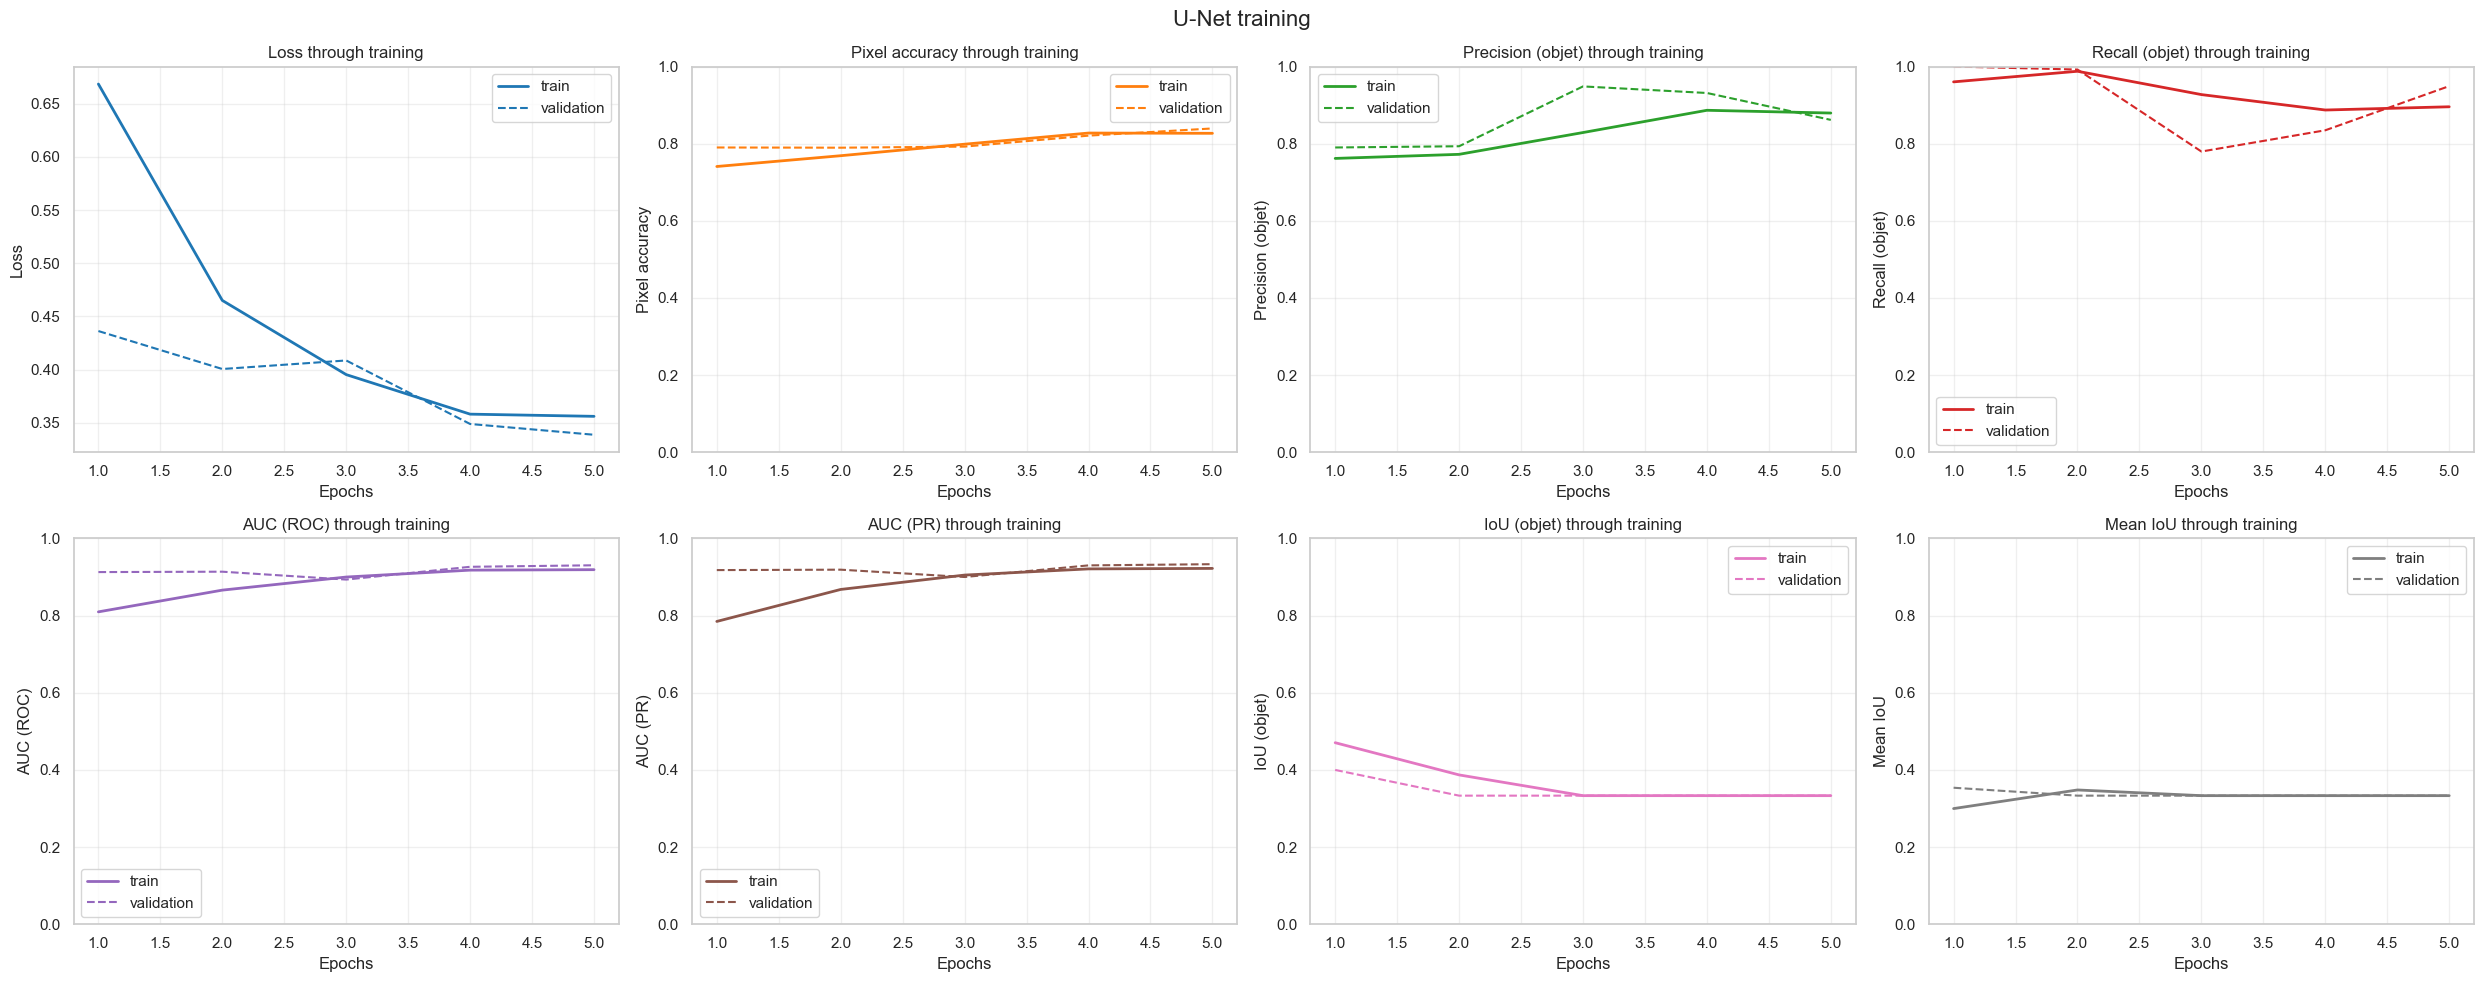

In [7]:
historic = pd.DataFrame(history.history)
epochs = range(1, len(historic) + 1)  # robuste si early stopping

metrics = [
    "loss", "accuracy", "precision", "recall",
    "auc", "auc_pr", "iou_fg", "mean_iou",
]
titles = {
    "loss": "Loss",
    "accuracy": "Pixel accuracy",
    "precision": "Precision (objet)",
    "recall": "Recall (objet)",
    "auc": "AUC (ROC)",
    "auc_pr": "AUC (PR)",
    "iou_fg": "IoU (objet)",
    "mean_iou": "Mean IoU",
}

figure, axes = plt.subplots(2, 4, figsize=(25, 10))
palette = sns.color_palette("tab10", n_colors=len(metrics))

for index, (metric_name, axis) in enumerate(zip(metrics, axes.flat)):
    if metric_name not in historic.columns:
        axis.set_visible(False)  # métrique absente de l'historique
        continue

    color = palette[index]
    axis.plot(epochs, historic[metric_name], lw=2, color=color, label="train")
    if "val_" + metric_name in historic.columns:
        axis.plot(epochs, historic["val_" + metric_name], ls="--", color=color, label="validation")

    if metric_name != "loss":
        axis.set_ylim(0, 1)
    axis.set_ylabel(titles[metric_name])
    axis.set_xlabel("Epochs")
    axis.set_title("%s through training" % titles[metric_name])
    axis.grid(alpha=0.3)
    axis.legend()

plt.suptitle("U-Net training", fontsize=16)
plt.tight_layout()
plt.show()

In [8]:
display(historic)

,loss,accuracy,precision,recall,auc,auc_pr,iou_fg,mean_iou,val_loss,val_accuracy,val_precision,val_recall,val_auc,val_auc_pr,val_iou_fg,val_mean_iou
0,0.668534,0.740811,0.761737,0.960168,0.809745,0.784915,0.470588,0.299810,0.436263,0.790100,0.790102,0.999952,0.912847,0.918006,0.400000,0.353846
1,0.465059,0.768771,0.772343,0.987653,0.866066,0.867841,0.387097,0.348094,0.400581,0.789564,0.793311,0.992112,0.913851,0.919084,0.333333,0.333333
2,0.395302,0.798632,0.828824,0.927219,0.899991,0.905089,0.333333,0.333333,0.408603,0.792374,0.948391,0.779607,0.893430,0.900078,0.333333,0.333333
3,0.358132,0.827521,0.886521,0.887203,0.917893,0.921106,0.333333,0.333333,0.348883,0.820802,0.931356,0.834687,0.926545,0.930214,0.333333,0.333333
4,0.356073,0.826849,0.879364,0.895621,0.919108,0.922374,0.333333,0.333333,0.338747,0.839456,0.861639,0.949201,0.930475,0.933313,0.333333,0.333333


In [9]:
y_test_one_hot = tf.one_hot(y_test, depth=2)
score = model.evaluate(X_test, y_test_one_hot, return_dict=True)

# Dice (= F1 pixel) déduit de la précision et du recall de la classe objet
dice = 2 * score["precision"] * score["recall"] / (score["precision"] + score["recall"] + 1e-8)

df_score = pd.DataFrame(
    {
        "Métrique": [
            "Loss",
            "Accuracy",
            "Precision (objet)",
            "Recall (objet)",
            "Dice / F1 (objet)",
            "IoU (objet)",
            "Mean IoU",
            "AUC (ROC)",
            "AUC (PR)",
        ],
        "Valeur": [
            score["loss"],
            score["accuracy"],
            score["precision"],
            score["recall"],
            dice,
            score["iou_fg"],
            score["mean_iou"],
            score["auc"],
            score["auc_pr"],
        ],
    }
).set_index("Métrique")

display(df_score.style.format("{:.4f}"))

1/1 [==============================] - 4s 4s/step - loss: 0.1933 - accuracy: 0.9107 - precision: 0.9639 - recall: 0.9384 - auc: 0.9792 - auc_pr: 0.9801 - iou_fg: 0.3333 - mean_iou: 0.3333


,Valeur
Métrique,
Loss,0.1933
Accuracy,0.9107
Precision (objet),0.9639
Recall (objet),0.9384
Dice / F1 (objet),0.9510
IoU (objet),0.3333
Mean IoU,0.3333
AUC (ROC),0.9792
AUC (PR),0.9801


## UNet simplifier 

&nbsp;&nbsp;&nbsp;&nbsp; Dans cette partie nous allons créer un model avec le meme format que UNet mais dans lequel nous mettrons moins de blocs. Cependant pour compenser la perte de performance dû à cette réduction nous allons remplacer les fonctions ReLu par des fonction SiLu. Nous allons aussi jouter une couche de batch noramlisation et une couche de drop out par blocs. Par ce nouveau réseau nous passerons de 31 millions de paramètre à 8 millions. 

In [22]:

def conv_block(x, filters):
    x = keras.layers.Conv2D(
        filters, 3, activation="silu", padding="valid"
    )(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.Dropout(0.2)(x)
    x = keras.layers.Conv2D(
        filters, 3, activation="silu", padding="valid"
    )(x)

    return x


def up_block(x, skip, filters, crop):
    x = keras.layers.Conv2DTranspose(
        filters, 2, strides=2, padding="valid"
    )(x)

    skip = keras.layers.Cropping2D(
        cropping=((crop, crop), (crop, crop))
    )(skip)

    x = keras.layers.Concatenate()([skip, x])

    return conv_block(x, filters)


def get_model_2(input_shape=(572, 572, 1), num_classes=2):

    inputs = keras.Input(shape=input_shape)  # 572 x 572 x 1

    # Encodeur
    x1 = conv_block(inputs, 64)  # 568 x 568
    x2 = conv_block(
        keras.layers.MaxPooling2D(2)(x1), 128
    )  # 280 x 280

    x3 = conv_block(
        keras.layers.MaxPooling2D(2)(x2), 256
    )  # 136 x 136

    # Bottleneck
    b = conv_block(
        keras.layers.MaxPooling2D(2)(x3), 512
    )  # 64 x 64

    # Décodeur
    d3 = up_block(b, x3, 256, crop=4)    # 124 x 124
    d2 = up_block(d3, x2, 128, crop=16)  # 244 x 244
    d1 = up_block(d2, x1, 64, crop=40)   # 484 x 484

    # Recadrage final : 484 -> 388
    d1 = keras.layers.Cropping2D(
        cropping=((48, 48), (48, 48))
    )(d1)  # 388 x 388

    # Couche de segmentation : 2 classes
    outputs = keras.layers.Conv2D(
        num_classes, 1, activation="softmax", padding="valid"
    )(d1)  # 388 x 388 x 2

    model = keras.Model(
        inputs, outputs, name="unet"
    )

    return model


model_2 = get_model_2()
model_2.summary()


Model: "unet"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_7 (InputLayer)           [(None, 572, 572, 1  0           []                               
                                )]                                                                
                                                                                                  
 conv2d_76 (Conv2D)             (None, 570, 570, 64  640         ['input_7[0][0]']                
                                )                                                                 
                                                                                                  
 batch_normalization_29 (BatchN  (None, 570, 570, 64  256        ['conv2d_76[0][0]']              
 ormalization)                  )                                                              

In [15]:
callback = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5)

n_epochs = 5
baches_size = 1

y_train_one_hot = tf.one_hot(y_train, depth=2)
y_val_one_hot = tf.one_hot(y_val, depth=2)

model_2.compile(
    optimizer="adam",              # garde les tiens
    loss="categorical_crossentropy",  # garde le tien
    metrics=[
        keras.metrics.CategoricalAccuracy(name="accuracy"),
        keras.metrics.Precision(class_id=1, name="precision"),
        keras.metrics.Recall(class_id=1, name="recall"),
        keras.metrics.AUC(name="auc"),
        keras.metrics.AUC(curve="PR", name="auc_pr"),
        keras.metrics.OneHotIoU(num_classes=2, target_class_ids=[1], name="iou_fg"),
        keras.metrics.OneHotMeanIoU(num_classes=2, name="mean_iou"),
    ],
)


history = model_2.fit(
    X_train,
    y_train_one_hot,
    epochs=n_epochs,
    batch_size=baches_size,
    validation_data=(X_val, y_val_one_hot),
    callbacks=[callback],
)

Epoch 1/5
24/24 [==============================] - 7s 195ms/step - loss: 0.3967 - accuracy: 0.8186 - precision: 0.8981 - recall: 0.8593 - auc: 0.9085 - auc_pr: 0.9094 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 2.5347 - val_accuracy: 0.7900 - val_precision: 0.7900 - val_recall: 1.0000 - val_auc: 0.7900 - val_auc_pr: 0.7526 - val_iou_fg: 0.5000 - val_mean_iou: 0.2500
Epoch 2/5
24/24 [==============================] - 4s 161ms/step - loss: 0.2936 - accuracy: 0.8693 - precision: 0.9019 - recall: 0.9297 - auc: 0.9472 - auc_pr: 0.9482 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 2.1905 - val_accuracy: 0.7900 - val_precision: 0.7900 - val_recall: 1.0000 - val_auc: 0.7935 - val_auc_pr: 0.7564 - val_iou_fg: 0.5000 - val_mean_iou: 0.2500
Epoch 3/5
24/24 [==============================] - 4s 161ms/step - loss: 0.2707 - accuracy: 0.8771 - precision: 0.9208 - recall: 0.9177 - auc: 0.9547 - auc_pr: 0.9562 - iou_fg: 0.3333 - mean_iou: 0.3333 - val_loss: 1.5436 - val_accuracy: 0.7900 - val_pre

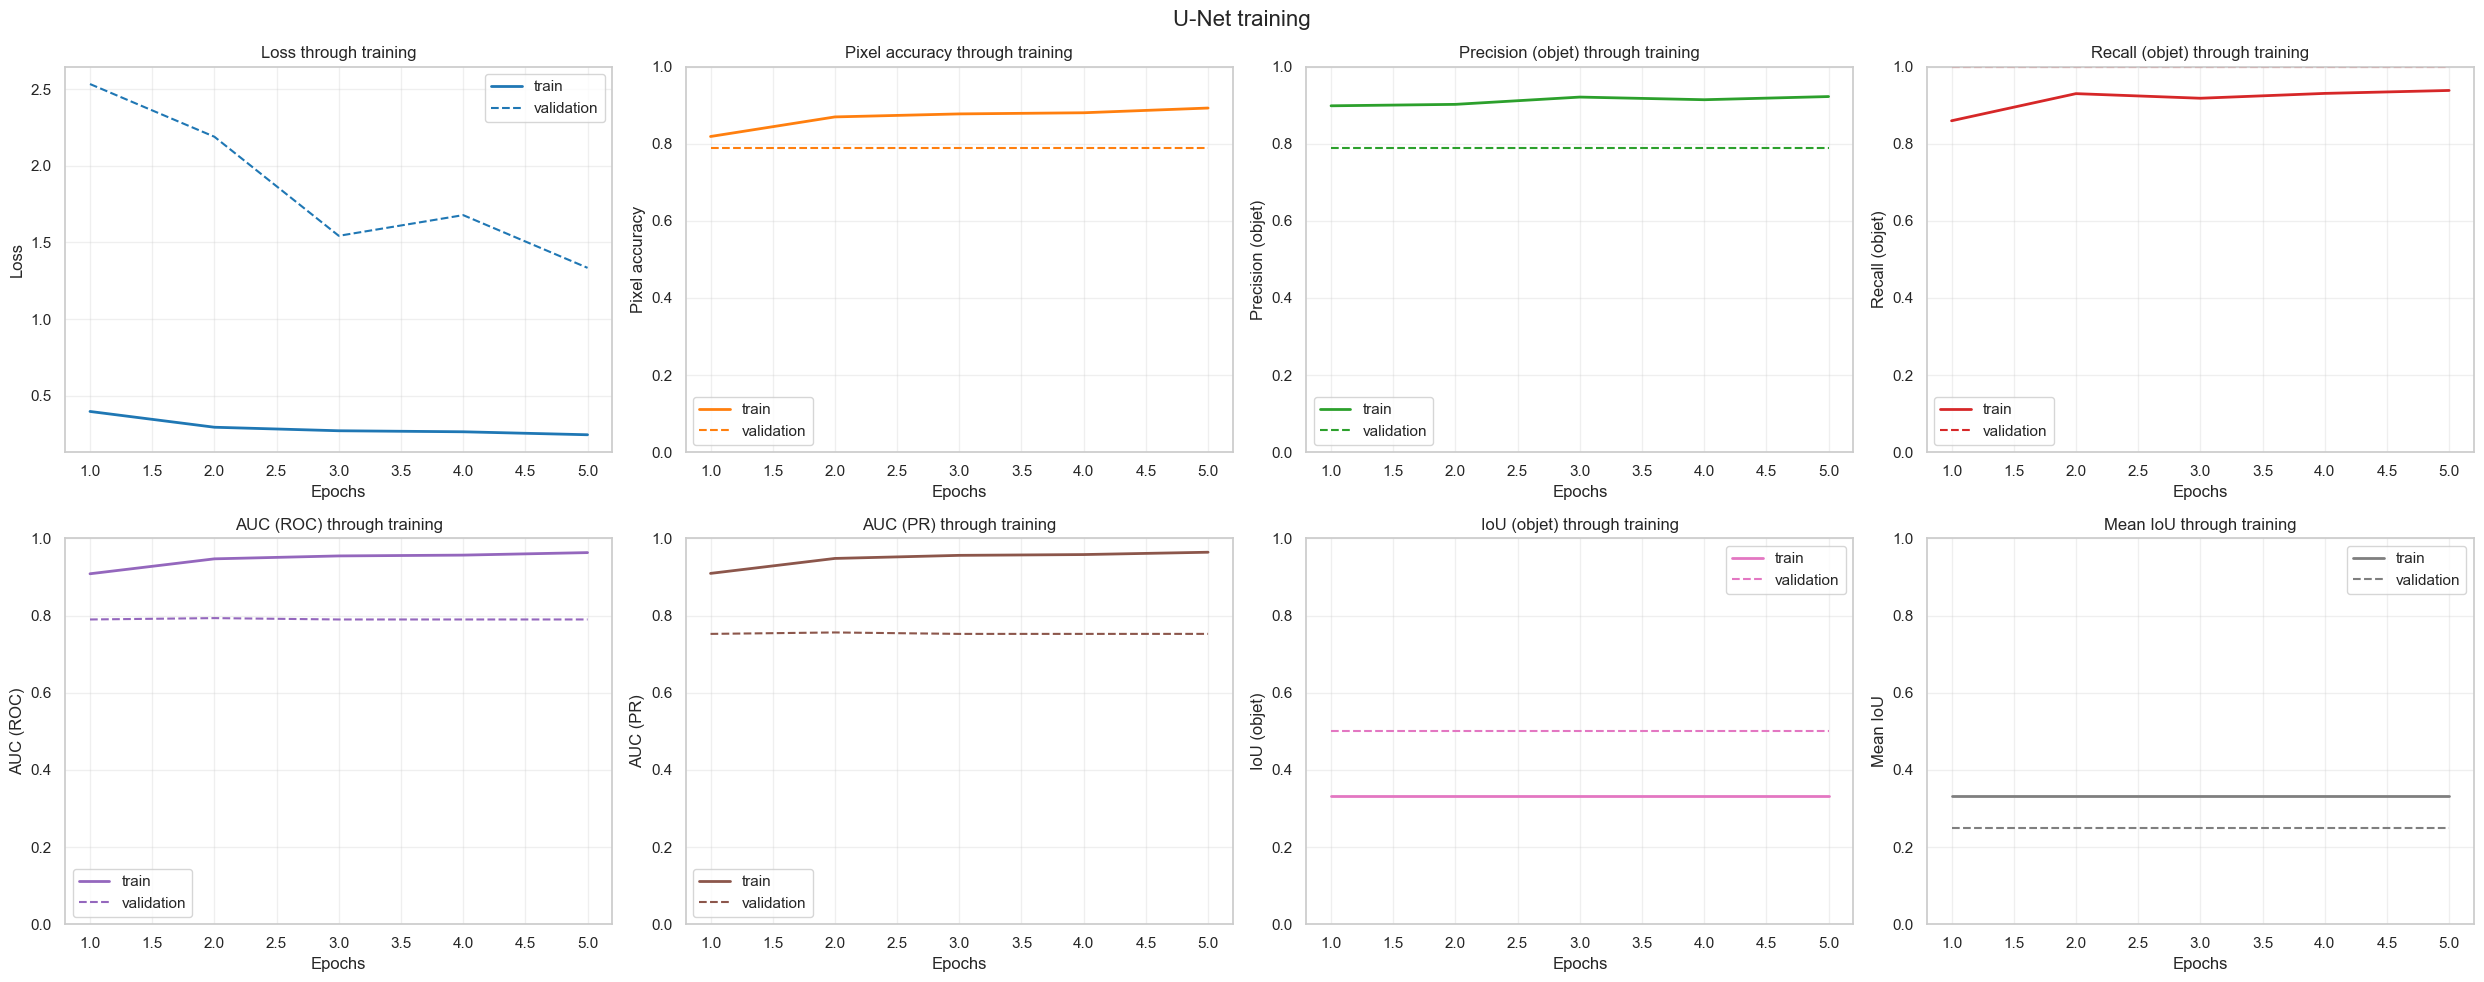

In [16]:
historic_2 = pd.DataFrame(history.history)
epochs = range(1, len(historic_2) + 1)  # robuste si early stopping

metrics = [
    "loss", "accuracy", "precision", "recall",
    "auc", "auc_pr", "iou_fg", "mean_iou",
]
titles = {
    "loss": "Loss",
    "accuracy": "Pixel accuracy",
    "precision": "Precision (objet)",
    "recall": "Recall (objet)",
    "auc": "AUC (ROC)",
    "auc_pr": "AUC (PR)",
    "iou_fg": "IoU (objet)",
    "mean_iou": "Mean IoU",
}

figure, axes = plt.subplots(2, 4, figsize=(25, 10))
palette = sns.color_palette("tab10", n_colors=len(metrics))

for index, (metric_name, axis) in enumerate(zip(metrics, axes.flat)):
    if metric_name not in historic_2.columns:
        axis.set_visible(False)  # métrique absente de l'historique
        continue

    color = palette[index]
    axis.plot(epochs, historic_2[metric_name], lw=2, color=color, label="train")
    if "val_" + metric_name in historic_2.columns:
        axis.plot(epochs, historic_2["val_" + metric_name], ls="--", color=color, label="validation")

    if metric_name != "loss":
        axis.set_ylim(0, 1)
    axis.set_ylabel(titles[metric_name])
    axis.set_xlabel("Epochs")
    axis.set_title("%s through training" % titles[metric_name])
    axis.grid(alpha=0.3)
    axis.legend()

plt.suptitle("U-Net training", fontsize=16)
plt.tight_layout()
plt.show()

In [17]:
display(historic_2)

,loss,accuracy,precision,recall,auc,auc_pr,iou_fg,mean_iou,val_loss,val_accuracy,val_precision,val_recall,val_auc,val_auc_pr,val_iou_fg,val_mean_iou
0,0.396698,0.818561,0.898135,0.859343,0.908473,0.909434,0.333333,0.333333,2.534682,0.790003,0.790003,1.0,0.790003,0.752628,0.5,0.25
1,0.293636,0.869334,0.901872,0.929665,0.947165,0.948220,0.333333,0.333333,2.190540,0.790003,0.790003,1.0,0.793526,0.756352,0.5,0.25
2,0.270662,0.877143,0.920760,0.917741,0.954727,0.956208,0.333333,0.333333,1.543583,0.790003,0.790003,1.0,0.790003,0.752628,0.5,0.25
3,0.263956,0.880104,0.913904,0.930286,0.956834,0.958264,0.333333,0.333333,1.678715,0.790003,0.790003,1.0,0.790003,0.752628,0.5,0.25
4,0.244524,0.892337,0.922116,0.937921,0.963333,0.964308,0.333333,0.333333,1.334436,0.790003,0.790003,1.0,0.790029,0.752656,0.5,0.25


In [18]:
y_test_one_hot = tf.one_hot(y_test, depth=2)
score_2 = model_2.evaluate(X_test, y_test_one_hot, return_dict=True)

# Dice (= F1 pixel) déduit de la précision et du recall de la classe objet
dice_2 = 2 * score_2["precision"] * score_2["recall"] / (score_2["precision"] + score_2["recall"] + 1e-8)

df_score_2 = pd.DataFrame(
    {
        "Métrique": [
            "Loss",
            "Accuracy",
            "Precision (objet)",
            "Recall (objet)",
            "Dice / F1 (objet)",
            "IoU (objet)",
            "Mean IoU",
            "AUC (ROC)",
            "AUC (PR)",
        ],
        "Valeur": [
            score_2["loss"],
            score_2["accuracy"],
            score_2["precision"],
            score_2["recall"],
            dice_2,
            score_2["iou_fg"],
            score_2["mean_iou"],
            score_2["auc"],
            score_2["auc_pr"],
        ],
    }
).set_index("Métrique")

display(df_score_2.style.format("{:.4f}"))

1/1 [==============================] - 11s 11s/step - loss: 0.4927 - accuracy: 0.9230 - precision: 0.9230 - recall: 1.0000 - auc: 0.9231 - auc_pr: 0.9032 - iou_fg: 0.5000 - mean_iou: 0.2500


,Valeur
Métrique,
Loss,0.4927
Accuracy,0.9230
Precision (objet),0.9230
Recall (objet),1.0000
Dice / F1 (objet),0.9600
IoU (objet),0.5000
Mean IoU,0.2500
AUC (ROC),0.9231
AUC (PR),0.9032


In [20]:
def add_dice(s):
    return 2 * s["precision"] * s["recall"] / (s["precision"] + s["recall"] + 1e-8)

scores = {"U-Net": score, "U-Net Simplifié": score_2}

compare = pd.DataFrame({
    "Model": list(scores.keys()),
    "Loss": [s["loss"] for s in scores.values()],
    "Accuracy": [s["accuracy"] for s in scores.values()],
    "Precision": [s["precision"] for s in scores.values()],
    "Recall": [s["recall"] for s in scores.values()],
    "Dice / F1": [add_dice(s) for s in scores.values()],
    "IoU (objet)": [s["iou_fg"] for s in scores.values()],
    "Mean IoU": [s["mean_iou"] for s in scores.values()],
    "AUC (ROC)": [s["auc"] for s in scores.values()],
    "AUC (PR)": [s["auc_pr"] for s in scores.values()],
}).set_index("Model")

display(
    compare.style
    .format("{:.4f}")
    .highlight_min(subset=["Loss"], color="grey")
    .highlight_max(subset=compare.columns.drop("Loss"), color="grey")
)

,Loss,Accuracy,Precision,Recall,Dice / F1,IoU (objet),Mean IoU,AUC (ROC),AUC (PR)
Model,,,,,,,,,
U-Net,0.1933,0.9107,0.9639,0.9384,0.9510,0.3333,0.3333,0.9792,0.9801
U-Net Simplifié,0.4927,0.9230,0.9230,1.0000,0.9600,0.5000,0.2500,0.9231,0.9032
